In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from skimage.exposure import match_histograms

In [2]:
# some sort of plotting function
def histPlot(images, labels=None, graph_color="#2F3F7F", img_color="gray"):
    n_img = len(images)
    fig, ax = plt.subplots(n_img, 2, figsize=(12, 4 * n_img), squeeze=False)

    for i in range(n_img):
        arr = np.asarray(images[i], dtype=np.float32)
        if arr.max() > 1:          # PIL / uint8 → scale to 0–1
            arr /= 255.0

        ax[i][0].imshow(arr, cmap=img_color, vmin=0, vmax=1, interpolation="nearest")
        ax[i][0].axis("off")
        if labels:
            ax[i][0].set_title(labels[i])
        ax[i][1].hist(arr.ravel(), bins=64, range=(0, 1), color=graph_color)

    plt.tight_layout()

# Image Analysis & Histogram Matching

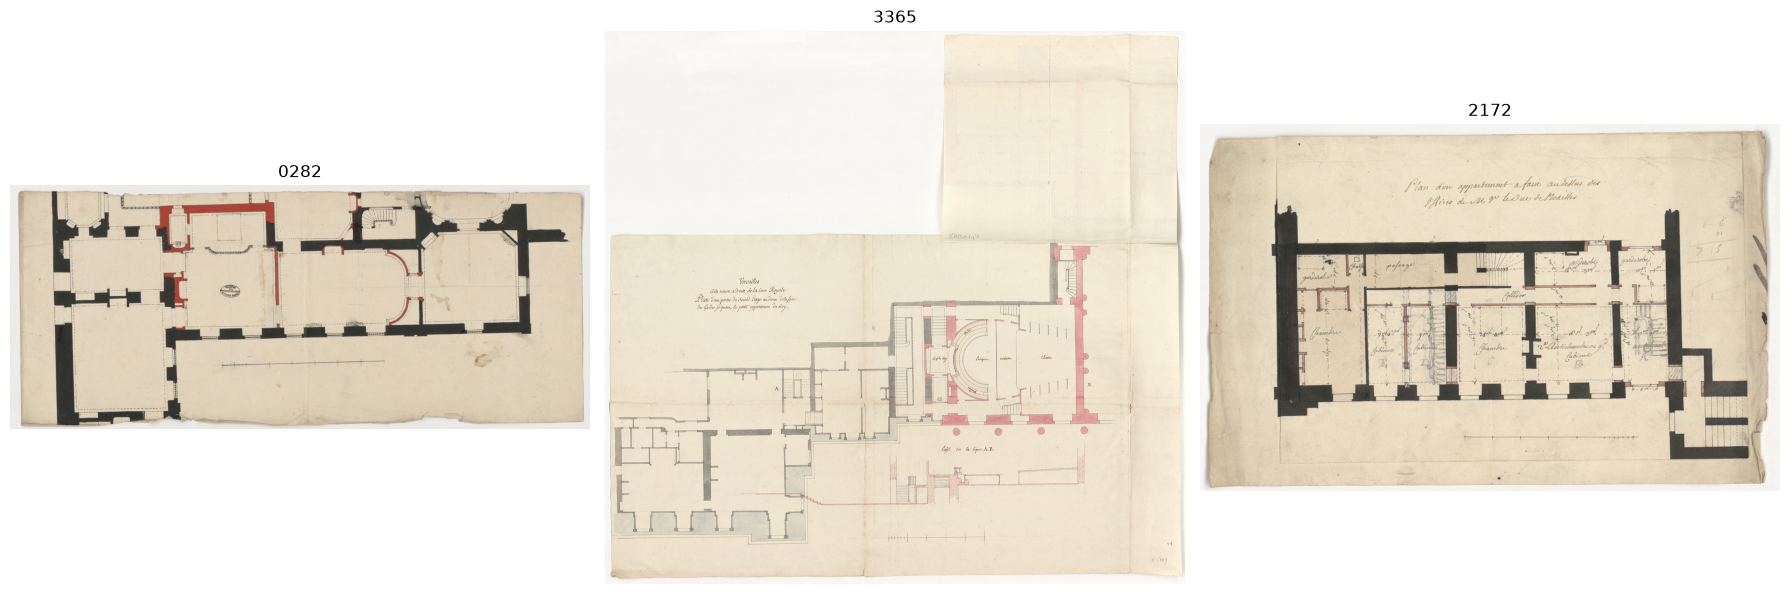

In [3]:
# Gather input images
in_dir = Path("./unprocessed")
out_dir = Path("./processed/colors")

img_ids = [
    # images to test:
    "0282", # Very bold with red walls
    "3365", # Faded image, some hashed red lines
    "2172"  # Subtle interior red walls
]
images = []

for id in img_ids:
    images.append(Image.open(in_dir / f"FRAN_0124_{id}_L.jpg"))

# Plot
fig, axes = plt.subplots(1, len(images), figsize=(6 * len(images), 6))

for ax, img, img_id in zip(axes, images, img_ids):
    ax.imshow(img.convert("RGB"))
    ax.set_title(img_id)
    ax.axis("off")

plt.tight_layout()
plt.show()



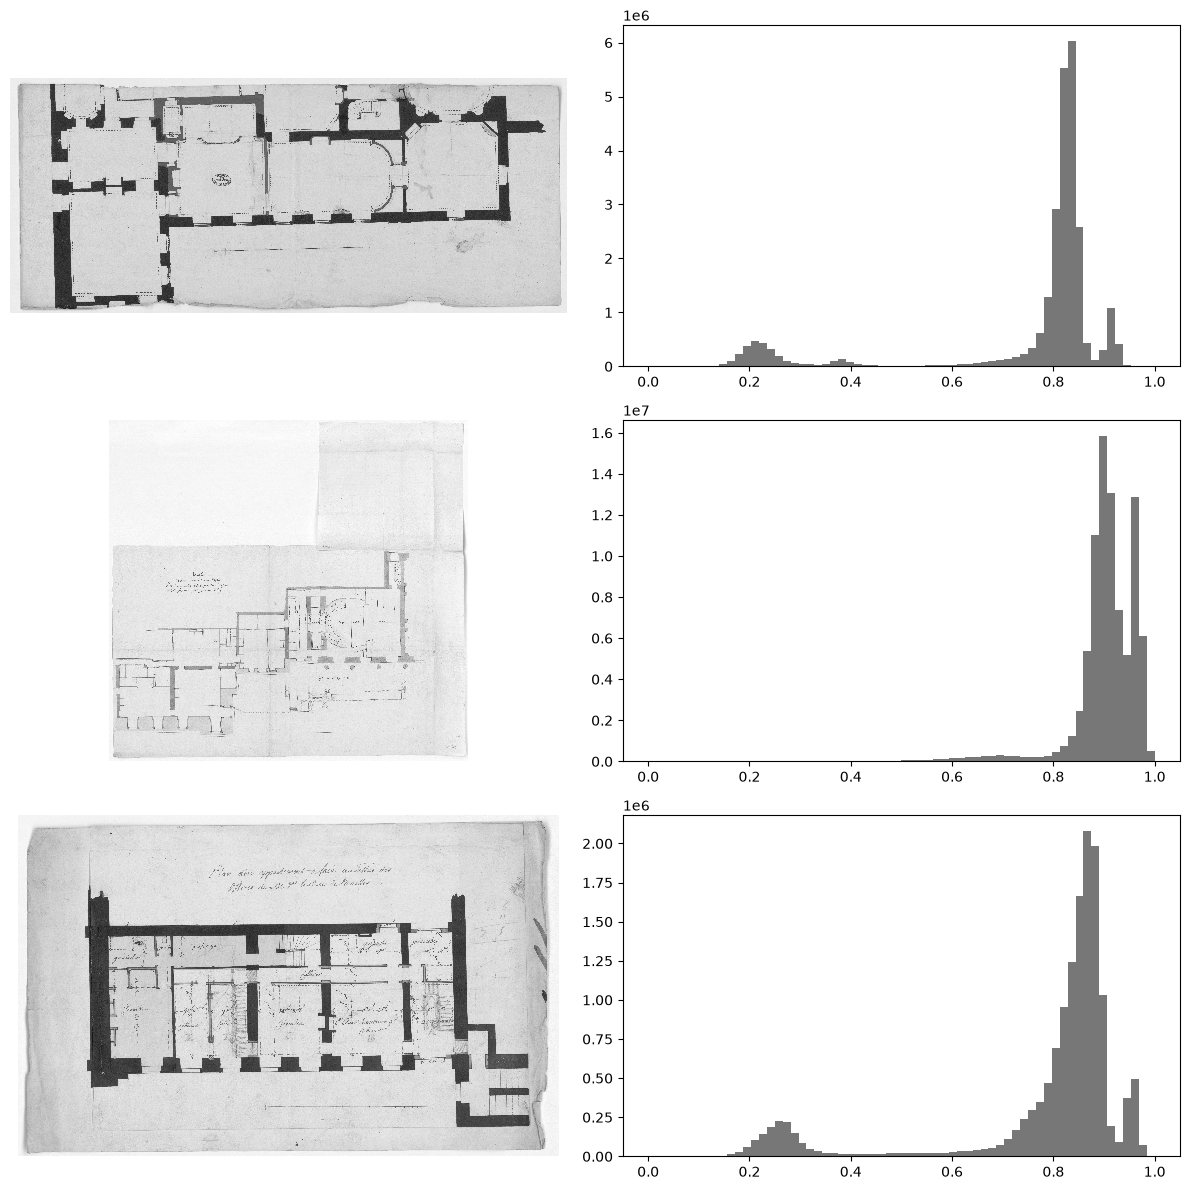

In [4]:
# Check out grayscale histogram
images_gray = [img.convert("L") for img in images]

histPlot(images_gray, graph_color="#777777")

Looking at the grayscale histograms, the bolder images have a clear little hump between 0.2 and 0.3. This must be the dark areas. Not particularly clear which spots are red, of course. The paler image does not have this clear split, however. Let's try to match to the histogram of the darker one.

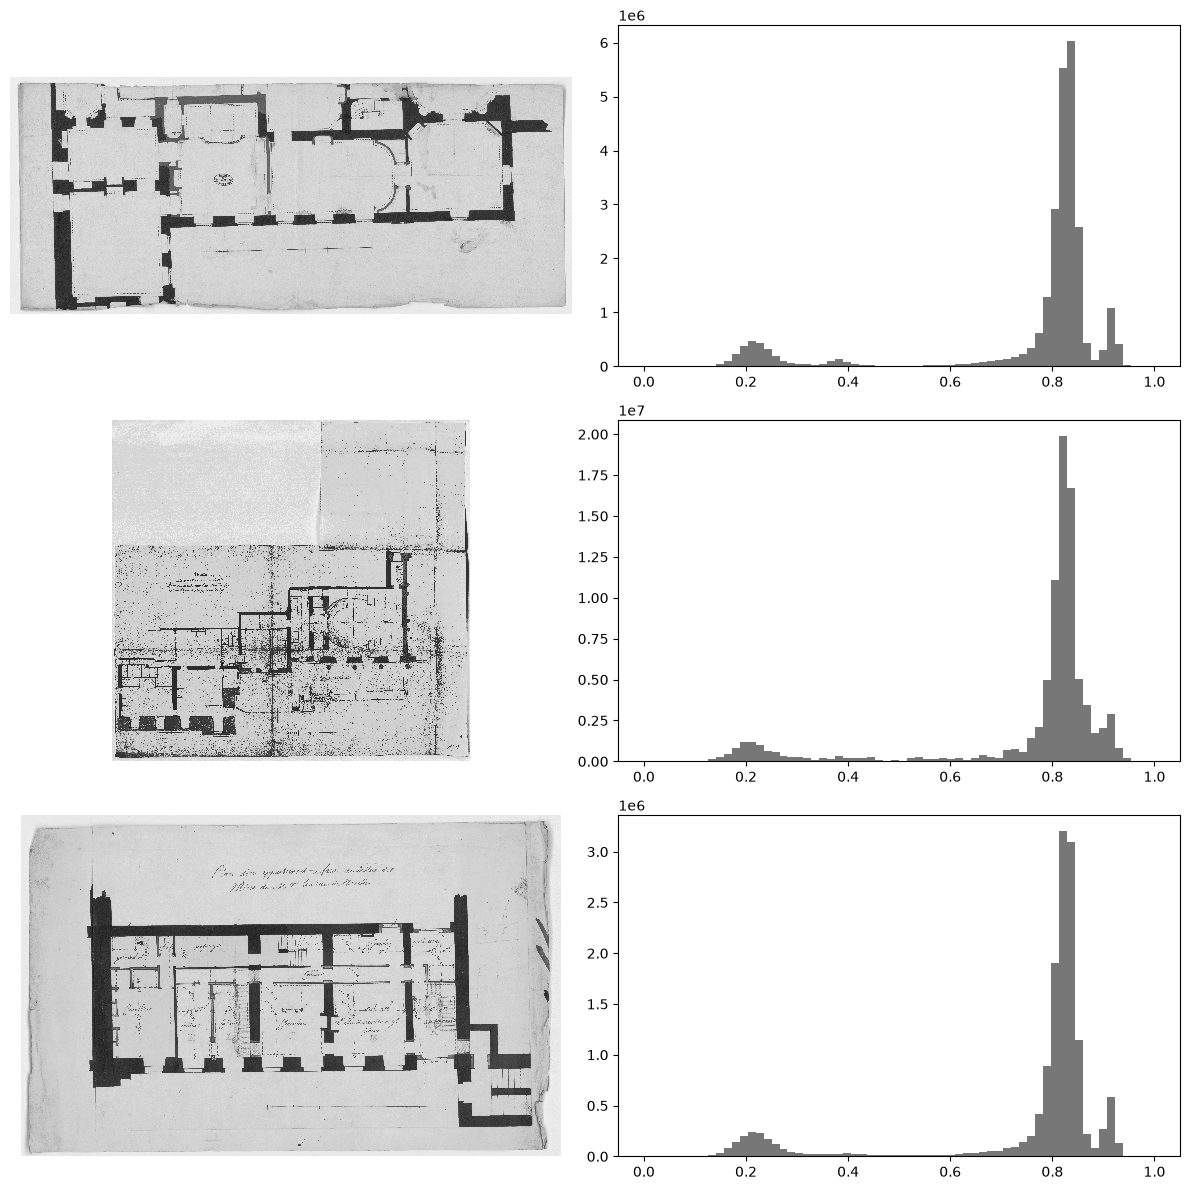

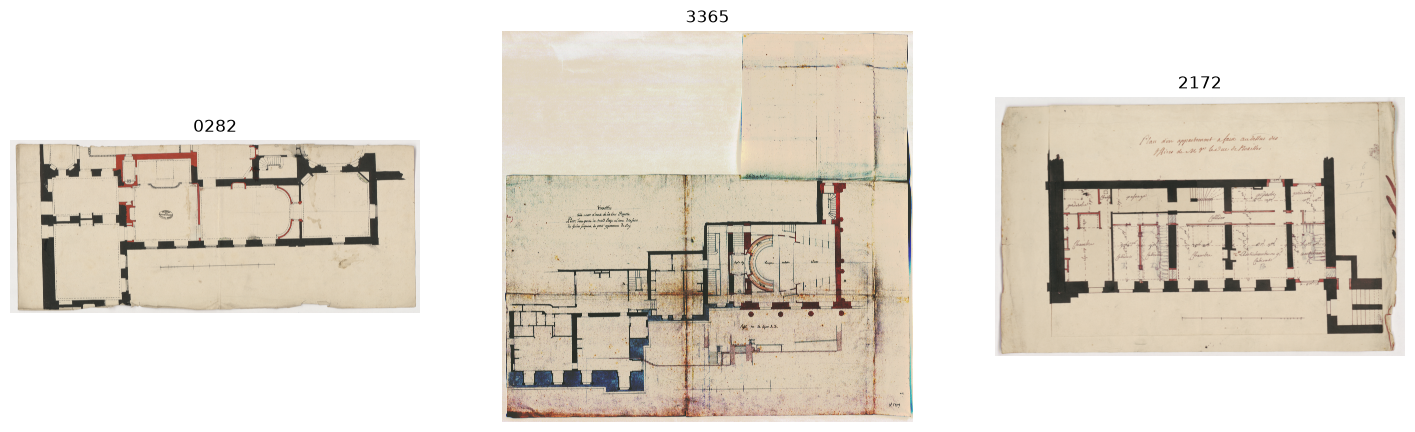

In [5]:
reference = np.asarray(images[0].convert("RGB"))
mimages = []

for img in images: # "match_histograms" is the important part
    mimages.append(Image.fromarray(match_histograms(np.asarray(img.convert("RGB")), reference, channel_axis=-1).clip(0, 255).astype(np.uint8)))

# Check out grayscale histogram
mimages_gray = [img.convert("L") for img in mimages]

histPlot(mimages_gray, graph_color="#777777")
# Plot normally
fig, axes = plt.subplots(1, len(mimages), figsize=(6 * len(images), 6))

for ax, img, img_id in zip(axes, mimages, img_ids):
    ax.imshow(img.convert("RGB"))
    ax.set_title(img_id)
    ax.axis("off")

Ew that didn't really work. Faded image gets these weird colors accentuating the creases. I'm guessing matching histograms for an RGB image does it individually for each color channel, may be better attempting to equalize individual channels. I want to do a few more experiments on this, however. 

# RGB Analysis

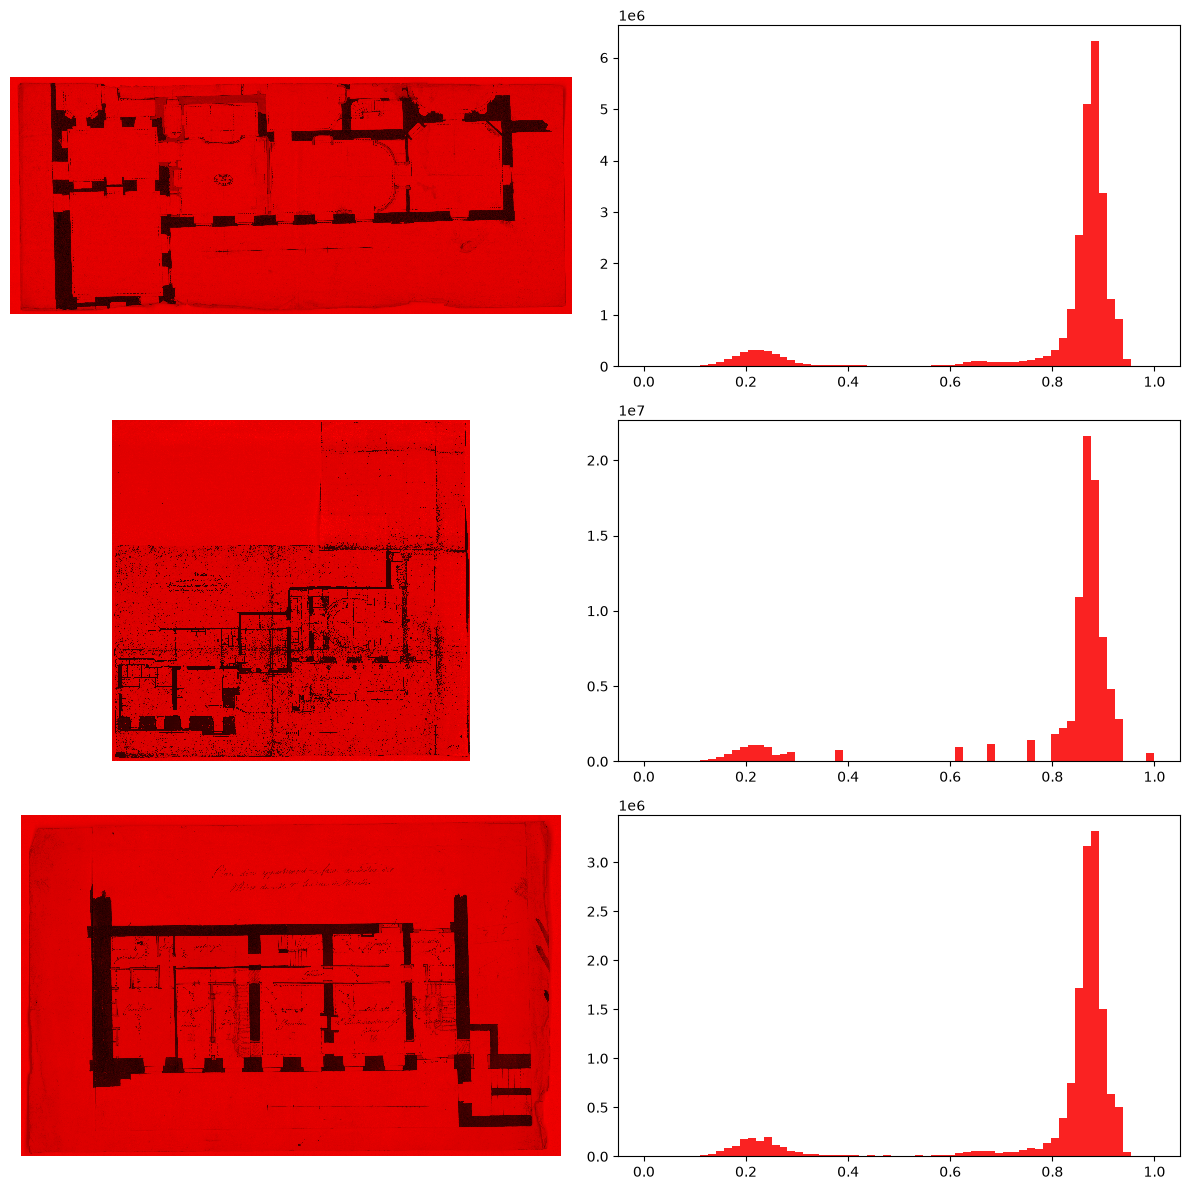

In [6]:
# Check out red histogram
mimages_red = [img.convert("RGB").getchannel("R") for img in mimages]

from matplotlib.colors import LinearSegmentedColormap
histPlot(mimages_red, graph_color="#FA2222", img_color=LinearSegmentedColormap.from_list("black_red", ["black", "red"]))

This gave me a lot less information than I thought it would, but it makes sense. The white/cream background of the image is going to have the same amount if not more red than the actual red spots. What if we looked at the green component?

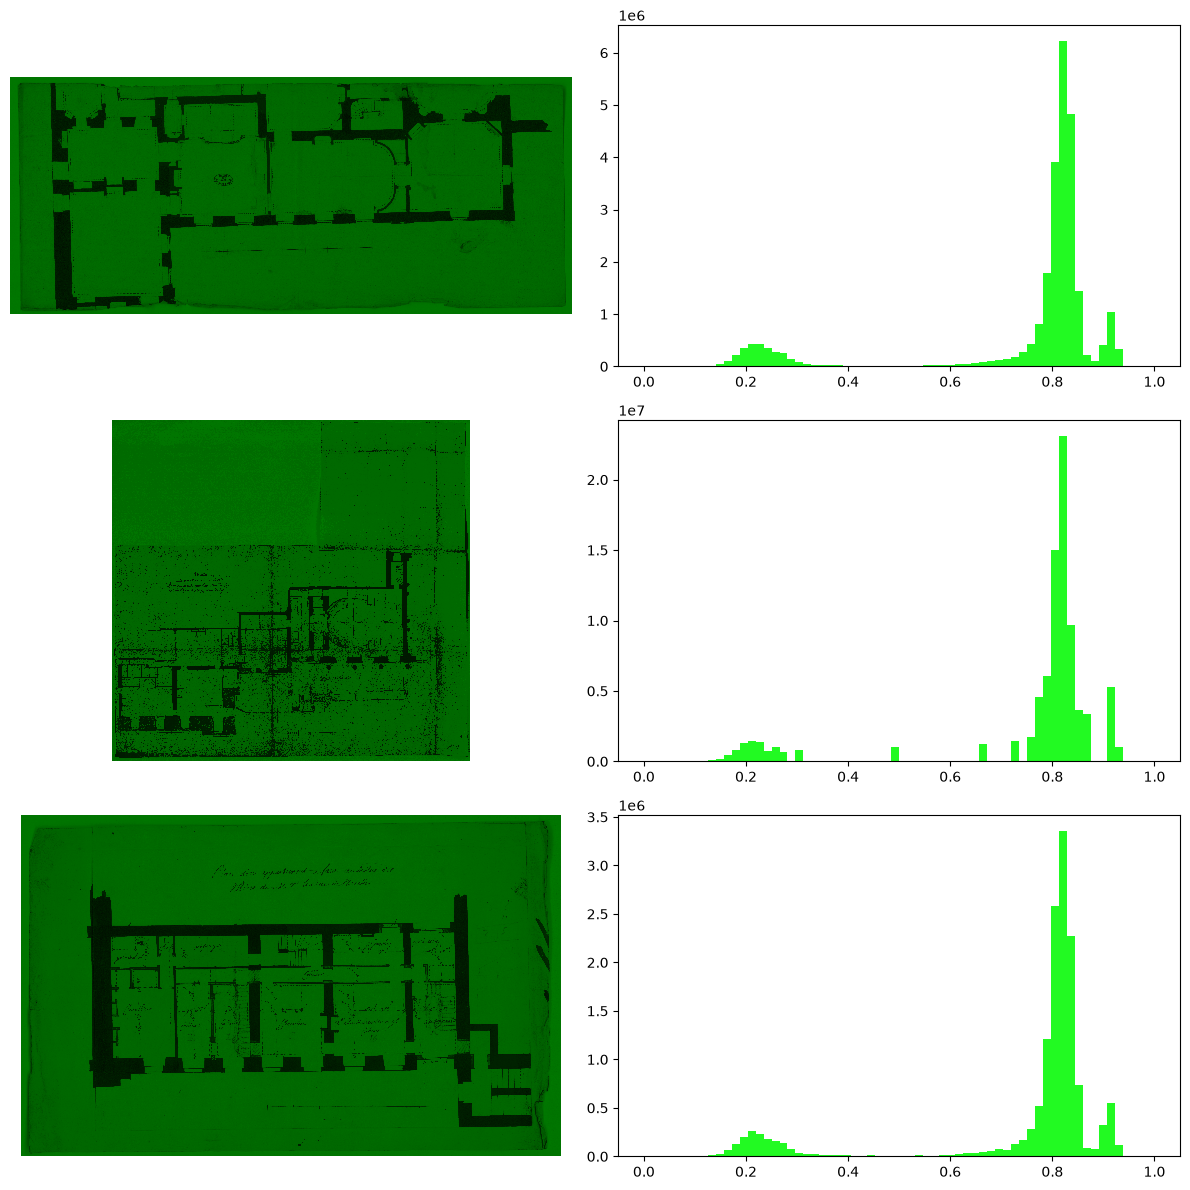

In [7]:
# Check out green histogram
mimages_green = [img.convert("RGB").getchannel("G") for img in mimages]

from matplotlib.colors import LinearSegmentedColormap
histPlot(mimages_green, graph_color="#22FA22", img_color=LinearSegmentedColormap.from_list("black_green", ["black", "green"]))

The parts that would be red in the original image are black in this green-extracted one. I'm thinking if we subtract this one from the red one, we will have isolated the red sections of the image.

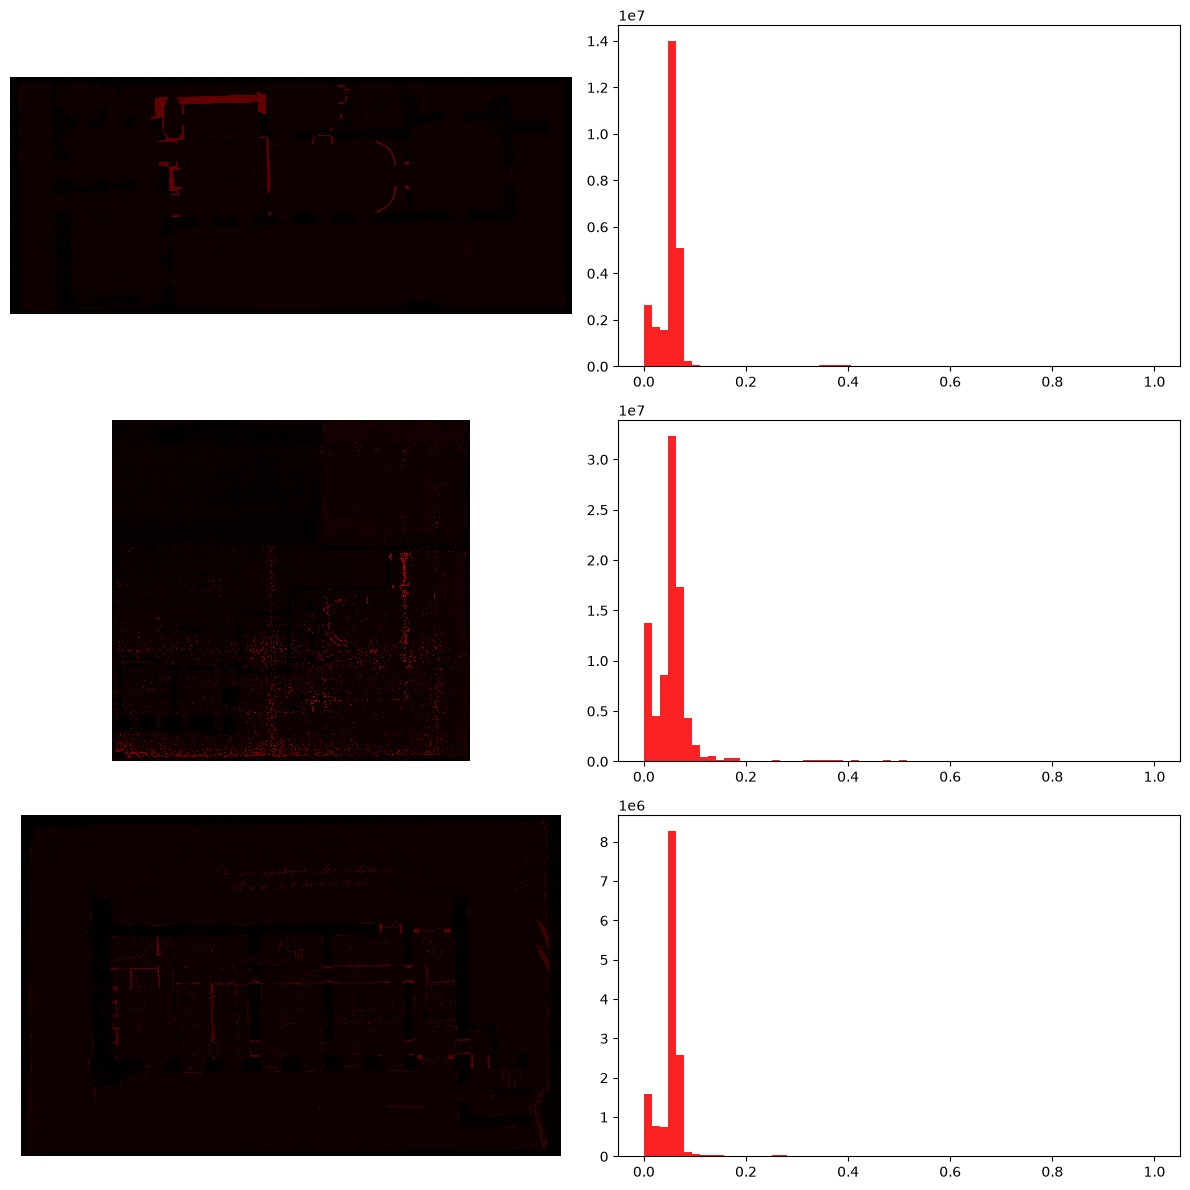

In [8]:
# Check out diff histogram
mimages_sub = [
    Image.fromarray(
        np.clip(np.asarray(r, dtype=np.int16) - np.asarray(b, dtype=np.int16), 0, 255)
        .astype(np.uint8)
    )
    for r, b in zip(mimages_red, mimages_green)
]

from matplotlib.colors import LinearSegmentedColormap
histPlot(mimages_sub, graph_color="#FA2222", img_color=LinearSegmentedColormap.from_list("black_red", ["black", "red"]))

With all of these, there is a slight bit of crumbs past the 0.2 mark. I predict this is our true red portions. Here's the idea for the algorithm to recolor:

- If `R - G > 0.2`: Red pixel
- Else if `G < 0.3`: Black pixel
- Else: White pixel

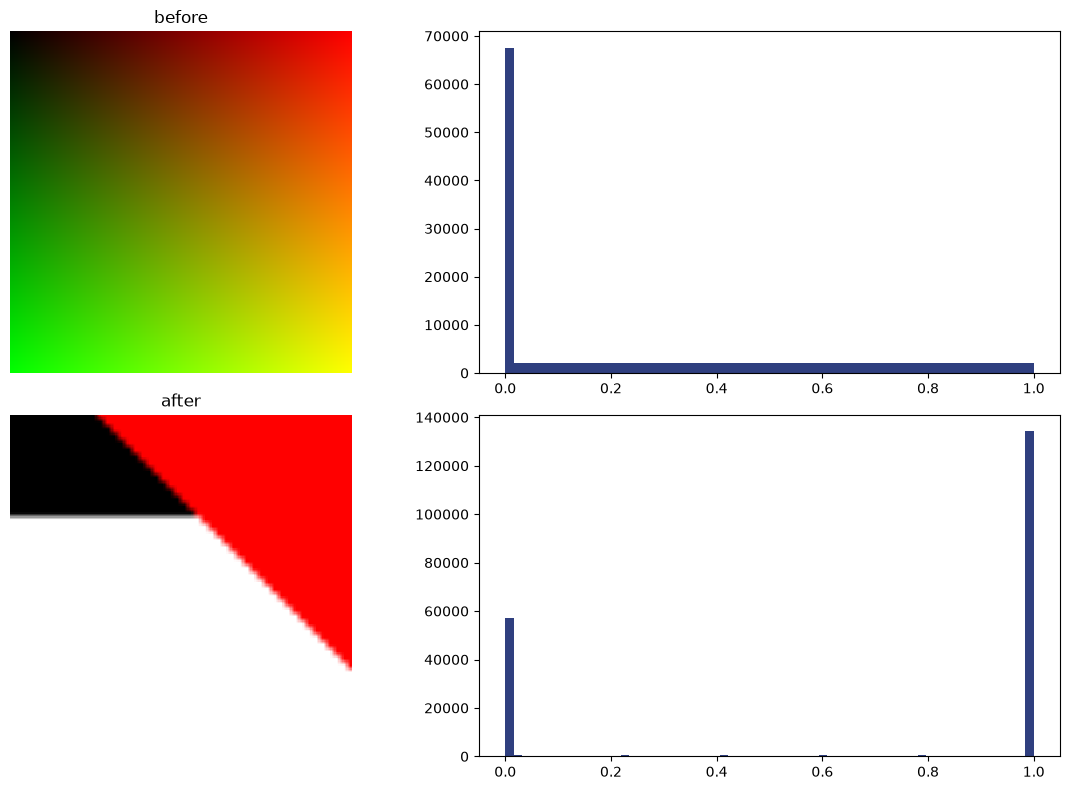

In [9]:
from PIL import ImageFilter

# Make LUT function
# I poked at the numbers a bit depending on result
def red_pop(r, g, b):
    if r - g > 0.25: #  Raising this threshold lowers red sensitivity
        return (1.0, 0.0, 0.0)  # red
    elif g < 0.3:    #  Raising this threshold raises black sensitivity
        return (0.0, 0.0, 0.0)  # black
    return (1.0, 1.0, 1.0)      # white


lut = ImageFilter.Color3DLUT.generate(50, red_pop) # The constant is like our resolution here

# Making a gradient image to show it on

h, w = 256, 256
x = np.linspace(0, 1, w)
y = np.linspace(0, 1, h)[:, None]

rgb = np.zeros((h, w, 3), dtype=np.float32)
rgb[..., 0] = x          # red channel
rgb[..., 1] = y          # blue channel

grad = Image.fromarray((rgb * 255).astype(np.uint8))
grad_proc = grad.convert("RGB").filter(lut)

histPlot([grad, grad_proc], labels=["before", "after"])

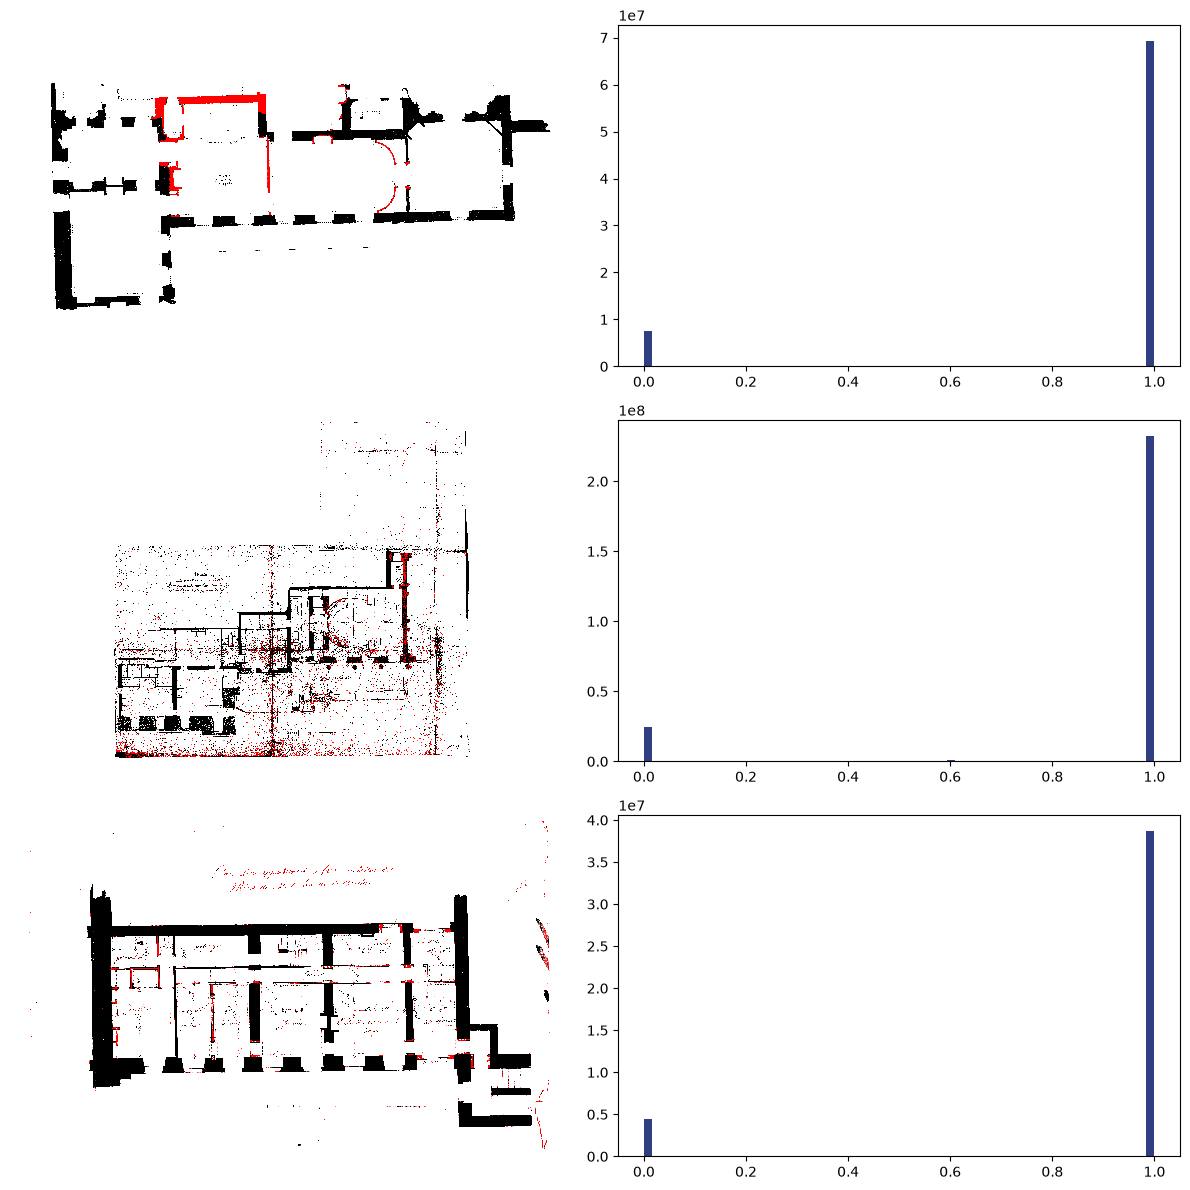

In [10]:
cc_images = []

for img in mimages: 
    cc_images.append(img.convert("RGB").filter(lut))

histPlot(cc_images)

First image looks great. Makes sense, this was the base for histogram matching
Second image looks like crap but we knew that
Third image looks decent, text is creating a lot of mess though.

Let's do some denoising techniques. Median filter?

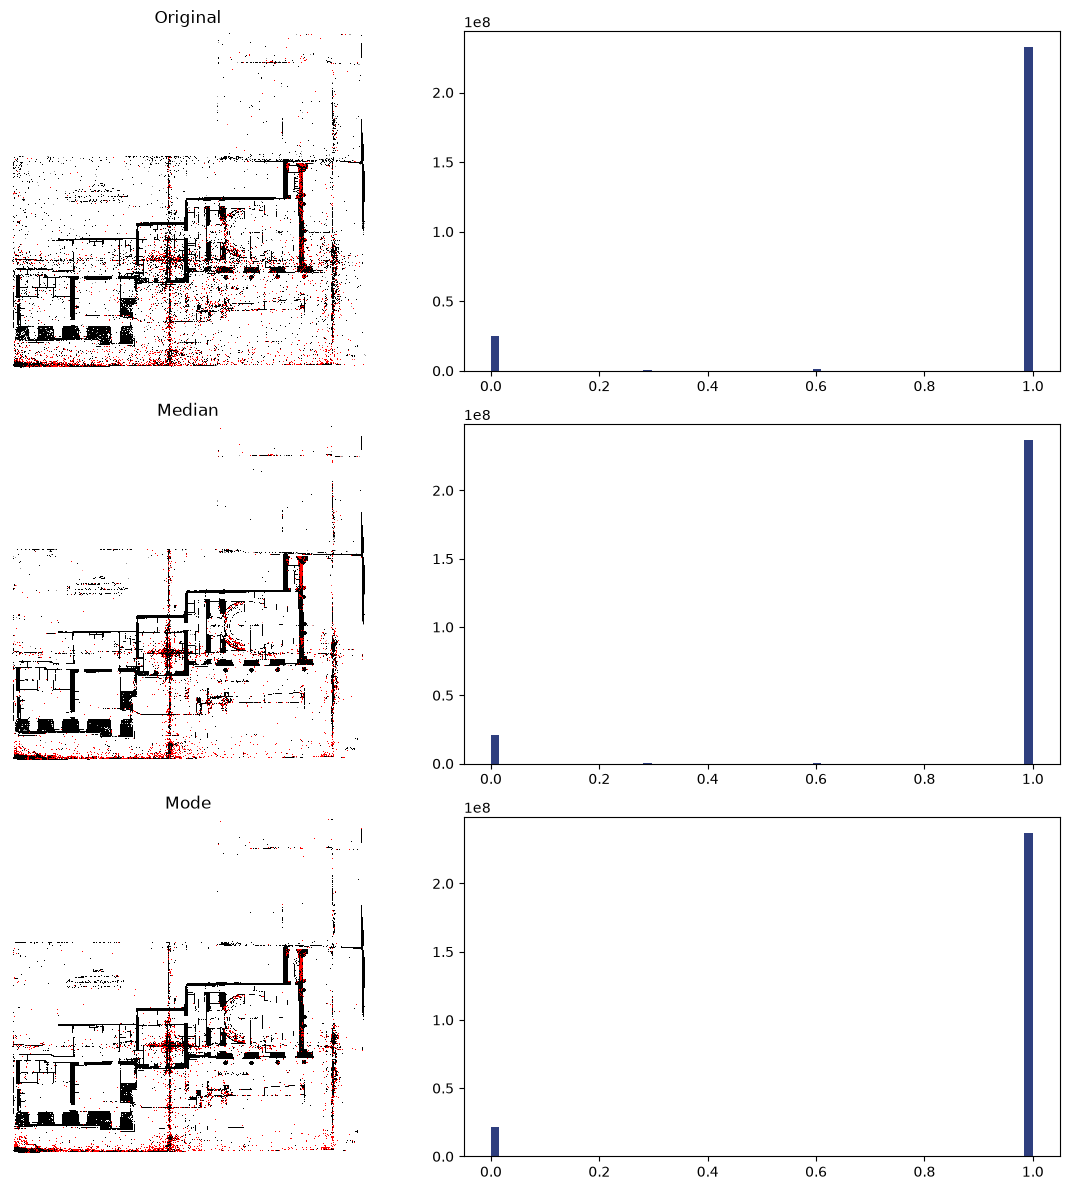

: 

In [ ]:
from skimage import filters, morphology

dull_schem = np.array(cc_images[1])

# Median
rect = morphology.footprint_rectangle((5, 5, 1)) # Extra dim for RGB
medi_schem = filters.median(dull_schem, rect)

# this should do mode which I also want to try
mode_schem = filters.rank.modal(dull_schem, rect)

histPlot([dull_schem, medi_schem, mode_schem], labels=["Original", "Median", "Mode"])

Decent, we can call the median filter version 1 but I want to try a different approach

# HSI Analysis

In [ ]:
from skimage import color

# We don't got HSI, you get HSV and like it
# Apparently V is max(r, g, b) as opposed to average.
reference = color.rgb2hsv(np.asarray(images[0].convert("RGB"))) 
himages = []

for img in images: # "match_histograms" is the important part
    hsv = color.rgb2hsv(np.asarray(img.convert("RGB")))
    hsv[..., 1:] = match_histograms(hsv[..., 1:], reference[..., 1:], channel_axis=-1)  # match only S and V, leave H alone
    himages.append(Image.fromarray((color.hsv2rgb(hsv.clip(0, 1)) * 255).clip(0, 255).astype(np.uint8))) 

# Check out grayscale histogram
himages_gray = [img.convert("L") for img in himages]

histPlot(himages_gray, graph_color="#777777")
# Plot normally
histPlot(himages)